In [1]:
import time
import random
import numpy as np
import tensorflow as tf
import tf_keras
import matplotlib.pyplot as plt
import tensorflow_model_optimization as tfmot

import os

# 1. Set environment variables BEFORE importing TensorFlow
os.environ['PYTHONHASHSEED'] = '10'
os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

import time
import random
import numpy as np
import tensorflow as tf
import tf_keras
import matplotlib.pyplot as plt
import tensorflow_model_optimization as tfmot

# 2. Seed all random number generators & enable deterministic ops
SEED = 10
tf.keras.utils.set_random_seed(SEED)
tf_keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

print("TensorFlow version:", tf.__version__)

I0000 00:00:1794730025.482973     662 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794730025.487011     662 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794730026.023254     662 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794730027.992540     662 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

TensorFlow version: 2.21.0


Processing files in '/root/lab_2_4/notebook/handDrawn' into MNIST format...

Converted 'number_0' -> Preprocessed Shape: (28, 28, 1)
Converted 'number_1' -> Preprocessed Shape: (28, 28, 1)
Converted 'number_2' -> Preprocessed Shape: (28, 28, 1)
Converted 'number_3' -> Preprocessed Shape: (28, 28, 1)


E0000 00:00:1794730038.711260     662 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
I0000 00:00:1794730038.711741     662 cuda_diagnostics.cc:171] verbose logging is disabled. Rerun with verbose logging (usually --v=1 or --vmodule=cuda_diagnostics=1) to get more diagnostic output from this module
I0000 00:00:1794730038.711744     662 cuda_diagnostics.cc:176] retrieving CUDA diagnostic information for host: jaime-Cyborg-15-B2RWFKG
I0000 00:00:1794730038.711747     662 cuda_diagnostics.cc:183] hostname: jaime-Cyborg-15-B2RWFKG
I0000 00:00:1794730038.711821     662 cuda_diagnostics.cc:190] libcuda reported version is: NOT_FOUND: was unable to find libcuda.so DSO loaded into this program. The library may be missing or provided via another object.
I0000 00:00:1794730038.711954     662 cuda_diagnostics.cc:194] kernel reported version is: 580.178.4


Converted 'number_4' -> Preprocessed Shape: (28, 28, 1)
Converted 'number_5' -> Preprocessed Shape: (28, 28, 1)
Converted 'number_6' -> Preprocessed Shape: (28, 28, 1)
Converted 'number_7' -> Preprocessed Shape: (28, 28, 1)
Converted 'number_8' -> Preprocessed Shape: (28, 28, 1)
Converted 'number_9' -> Preprocessed Shape: (28, 28, 1)

Final MNIST Dataset Batch Tensor Shape: (10, 28, 28, 1)
Data Type: <dtype: 'float32'>
Value Range: [0.00, 1.00]



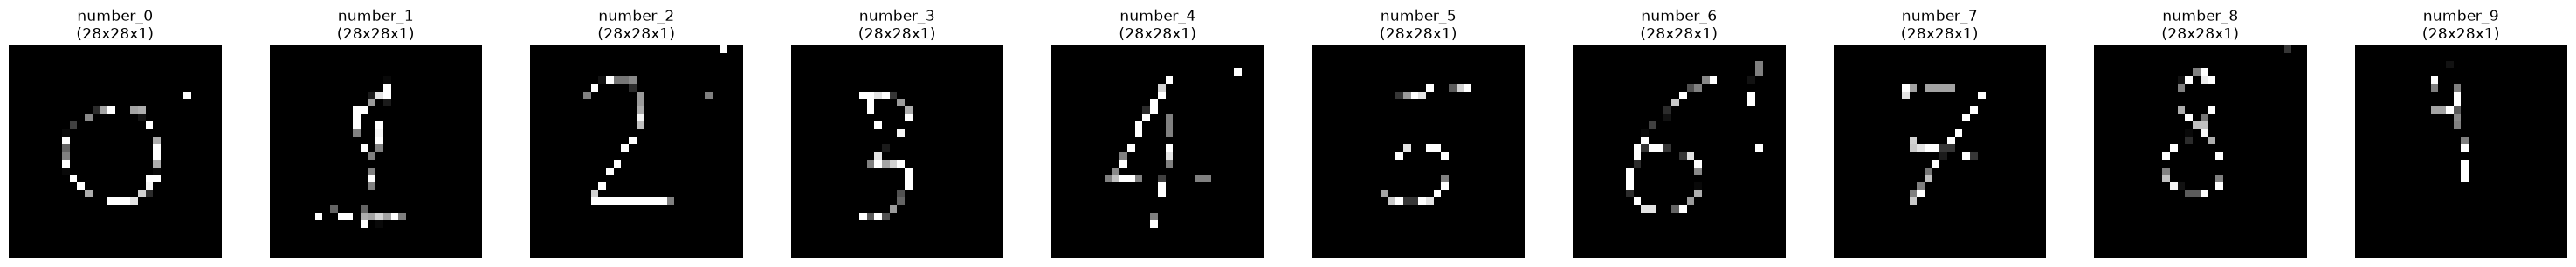

In [2]:
import os
import matplotlib.pyplot as plt
import tensorflow as tf

directory_path = "/root/lab_2_4/notebook/handDrawn"
char_map = {".": 0.0, "#": 1.0, "0": 0.0, "1": 1.0}

processed_tensors = []
filenames = []
labels_ofData = []
# -------------------------------------------------------------
# 1. PROCESS AND PREPROCESS INTO MNIST FORMAT
# -------------------------------------------------------------
if os.path.exists(directory_path):
    print(f"Processing files in '{directory_path}' into MNIST format...\n")

    for filename in sorted(os.listdir(directory_path)):
        full_path = os.path.join(directory_path, filename)

        if os.path.isfile(full_path):
            try:
                with open(full_path, "r", encoding="utf-8", errors="replace") as f:
                    content_str = f.read()


                # Extract binary values
                data_list = [char_map[c] for c in content_str if c in char_map]
                tensor_1d = tf.convert_to_tensor(data_list, dtype=tf.float32)

                # Reshape to original 2D dimension
                if tensor_1d.shape[0] == 240 * 280:
                    tensor_2d = tf.reshape(tensor_1d, (240, 280))
                elif tensor_1d.shape[0] == 120 * 140:
                    tensor_2d = tf.reshape(tensor_1d, (120, 140))
                else:
                    continue  # Skip unhandled files

                tensor_3d = tf.expand_dims(tensor_2d, axis=-1)

                # Resize to MNIST size (28x28) using bilinear interpolation
                mnist_tensor = tf.image.resize(
                    tensor_3d, [28, 28], method=tf.image.ResizeMethod.BILINEAR
                )

                if "lcd" in filename.lower():
                    mnist_tensor = 1.0 - mnist_tensor

                labels_ofData.append(int(full_path[-1]))
                processed_tensors.append(mnist_tensor)
                filenames.append(filename)
                print(
                    f"Converted '{filename}' -> Preprocessed Shape: {mnist_tensor.shape}"
                )

            except Exception as e:
                print(f"Could not process '{filename}': {e}")

# -------------------------------------------------------------
# 2. BATCH INTO A SINGLE TENSOR (N, 28, 28, 1)
# -------------------------------------------------------------
if processed_tensors:
    # Stack list of (28, 28, 1) tensors into a single (N, 28, 28, 1) batch
    mnist_batch = tf.stack(processed_tensors, axis=0)

    print("\n" + "=" * 50)
    print(f"Final MNIST Dataset Batch Tensor Shape: {mnist_batch.shape}")
    print(f"Data Type: {mnist_batch.dtype}")
    print(
        f"Value Range: [{tf.reduce_min(mnist_batch):.2f}, {tf.reduce_max(mnist_batch):.2f}]"
    )
    print("=" * 50 + "\n")

    # -------------------------------------------------------------
    # 3. VISUALIZE MNIST FORMATTED IMAGES
    # -------------------------------------------------------------
    num_files = len(filenames)
    fig, axes = plt.subplots(1, num_files, figsize=(3 * num_files, 3))

    if num_files == 1:
        axes = [axes]

    for i, (ax, name) in enumerate(zip(axes, filenames)):
        # Squeeze channel dim for matplotlib display: (28, 28, 1) -> (28, 28)
        img_disp = tf.squeeze(mnist_batch[i]).numpy()

        ax.imshow(img_disp, cmap="gray")
        ax.set_title(f"{name}\n(28x28x1)")
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No valid files processed.")

## loading the data

In [3]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
print(np.newaxis)
# Normalize to [0, 1] and add the channel dimension Conv2D expects
x_train = (x_train / 255.0).astype("float32")[..., np.newaxis]
x_test  = (x_test  / 255.0).astype("float32")[..., np.newaxis]

print("x_train:", x_train.shape, " x_test:", x_test.shape)
y_handDrawn = np.array(labels_ofData, dtype=np.int32)         # Shape: (N,)
print((y_handDrawn))

None
x_train: (60000, 28, 28, 1)  x_test: (10000, 28, 28, 1)
[0 1 2 3 4 5 6 7 8 9]


## I made the CNN from the lab bigger here

In [4]:
def build_modelOGremix(
    num_filters1=8, 
    num_filters2=16, 
    num_filters3=32, 
    dense_units1=64, 
    dense_units2=32,
    activation="relu", 
    dropout=0.0
):
    layers = [
        # Layer 1: Input (28, 28, 1) -> Conv -> MaxPool -> Output (14, 14, 8)
        tf_keras.layers.Conv2D(filters=num_filters1, kernel_size=3, padding='same', activation=activation, input_shape=(28, 28, 1)),
        tf_keras.layers.MaxPool2D(pool_size=(2, 2)),
        
        # Layer 2: Output (7, 7, 16)
        tf_keras.layers.Conv2D(filters=num_filters2, kernel_size=3, padding='same', activation=activation),
        tf_keras.layers.MaxPool2D(pool_size=(2, 2)),

        
        # Layer 3: Output (3, 3, 32)
        tf_keras.layers.Conv2D(filters=num_filters3, kernel_size=3, activation=activation),
        tf_keras.layers.MaxPool2D(pool_size=(2, 2)),
        
        tf_keras.layers.Flatten(),
        
        tf_keras.layers.Dense(dense_units1, activation=activation),
        tf_keras.layers.Dense(dense_units2, activation=activation)
    ]
    
    # Conditionally add Dropout before final classification
    if dropout > 0:
        layers.append(tf_keras.layers.Dropout(dropout))
        
    # Output layer for 10 classes
    layers.append(tf_keras.layers.Dense(10, activation='softmax'))
    
    return tf_keras.models.Sequential(layers)

modelOGremix = build_modelOGremix()
modelOGremix.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 28, 28, 8)         80        
                                                                 
 max_pooling2d (MaxPooling2  (None, 14, 14, 8)         0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 14, 14, 16)        1168      
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 7, 7, 16)          0         
 g2D)                                                            
                                                                 
 conv2d_2 (Conv2D)           (None, 5, 5, 32)          4640      
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 2, 2, 32)          0

In [5]:
# TODO 2: compile and fit the model, capturing the returned History object
modelOGremix.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
              metrics=['accuracy'])

history = modelOGremix.fit(x_train, y_train, epochs=5, 
                    validation_data=(x_test, y_test))


Epoch 1/5
1870/1875 [============================>.] - ETA: 0s - loss: 0.2654 - accuracy: 0.9175

E0000 00:00:1794668603.037054     517 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_17}}


1875/1875 [==============================] - 11s 5ms/step - loss: 0.2650 - accuracy: 0.9177 - val_loss: 0.0936 - val_accuracy: 0.9696
Epoch 2/5
1875/1875 [==============================] - 7s 4ms/step - loss: 0.0794 - accuracy: 0.9756 - val_loss: 0.0591 - val_accuracy: 0.9809
Epoch 3/5
1875/1875 [==============================] - 6s 3ms/step - loss: 0.0582 - accuracy: 0.9820 - val_loss: 0.0509 - val_accuracy: 0.9836
Epoch 4/5
1875/1875 [==============================] - 6s 3ms/step - loss: 0.0473 - accuracy: 0.9849 - val_loss: 0.0451 - val_accuracy: 0.9854
Epoch 5/5
1875/1875 [==============================] - 6s 3ms/step - loss: 0.0394 - accuracy: 0.9873 - val_loss: 0.0578 - val_accuracy: 0.9820


## original CNN from the lab

In [10]:
def build_modelOG(num_filters1=8, num_filters2=16, dense_units=32,
                 activation="relu", dropout=0.0):
    
    layers = [
        # Added input_shape to the first layer
        tf_keras.layers.Conv2D(filters=num_filters1, kernel_size=3, activation=activation, input_shape=(28, 28, 1)),
        tf_keras.layers.MaxPool2D(pool_size=(2,2)),
        tf_keras.layers.Conv2D(filters=num_filters2, kernel_size=3, activation=activation),
        tf_keras.layers.MaxPool2D(pool_size=(2,2)),
        tf_keras.layers.Flatten(),
        # Used the dense_units parameter instead of hardcoding 32
        tf_keras.layers.Dense(dense_units, activation=activation)
    ]
    
    if dropout > 0:
        layers.append(tf_keras.layers.Dropout(dropout))
        
    layers.append(tf_keras.layers.Dense(10, activation='softmax'))
    tf_keras.models
    return tf_keras.models.Sequential(layers)

modelOG = build_modelOG()
modelOG.summary()

# TODO 2: compile and fit the model, capturing the returned History object
modelOG.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
              metrics=['accuracy']) #learning rate defaults to 0.001 https://keras.io/api/optimizers/adam/

history = modelOG.fit(x_train, y_train, epochs=5, 
                    validation_data=(x_test, y_test))




Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 26, 26, 8)         80        
                                                                 
 max_pooling2d (MaxPooling2  (None, 13, 13, 8)         0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 11, 11, 16)        1168      
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 5, 5, 16)          0         
 g2D)                                                            
                                                                 
 flatten (Flatten)           (None, 400)               0         
                                                                 
 dense (Dense)               (None, 32)                1

E0000 00:00:1794732322.059952     662 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_17}}


1875/1875 [==============================] - 5s 2ms/step - loss: 0.2402 - accuracy: 0.9291 - val_loss: 0.0766 - val_accuracy: 0.9771
Epoch 2/5
1875/1875 [==============================] - 4s 2ms/step - loss: 0.0785 - accuracy: 0.9752 - val_loss: 0.0572 - val_accuracy: 0.9816
Epoch 3/5
1875/1875 [==============================] - 4s 2ms/step - loss: 0.0608 - accuracy: 0.9811 - val_loss: 0.0588 - val_accuracy: 0.9818
Epoch 4/5
1875/1875 [==============================] - 4s 2ms/step - loss: 0.0497 - accuracy: 0.9848 - val_loss: 0.0654 - val_accuracy: 0.9784
Epoch 5/5
1875/1875 [==============================] - 4s 2ms/step - loss: 0.0425 - accuracy: 0.9864 - val_loss: 0.0450 - val_accuracy: 0.9859


In [8]:

modelLearnRate = build_modelOG()
modelLearnRate.summary()

# TODO 2: compile and fit the model, capturing the returned History object
modelLearnRate.compile(optimizer=tf_keras.optimizers.Adam(learning_rate=0.05),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
              metrics=['accuracy']) #learning rate defaults to 0.001 https://keras.io/api/optimizers/adam/

history = modelLearnRate.fit(x_train, y_train, epochs=5, 
                    validation_data=(x_test, y_test))



Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_5 (Conv2D)           (None, 26, 26, 8)         80        
                                                                 
 max_pooling2d_5 (MaxPoolin  (None, 13, 13, 8)         0         
 g2D)                                                            
                                                                 
 conv2d_6 (Conv2D)           (None, 11, 11, 16)        1168      
                                                                 
 max_pooling2d_6 (MaxPoolin  (None, 5, 5, 16)          0         
 g2D)                                                            
                                                                 
 flatten_2 (Flatten)         (None, 400)               0         
                                                                 
 dense_5 (Dense)             (None, 32)               

Epoch 1/5
1862/1875 [============================>.] - ETA: 0s - loss: 2.3095 - accuracy: 0.1047

E0000 00:00:1794668655.469380     517 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_17}}


1875/1875 [==============================] - 5s 2ms/step - loss: 2.3094 - accuracy: 0.1046 - val_loss: 2.3090 - val_accuracy: 0.0958
Epoch 2/5
1875/1875 [==============================] - 5s 2ms/step - loss: 2.3078 - accuracy: 0.1044 - val_loss: 2.3163 - val_accuracy: 0.1009
Epoch 3/5
1875/1875 [==============================] - 4s 2ms/step - loss: 2.3080 - accuracy: 0.1044 - val_loss: 2.3074 - val_accuracy: 0.0980
Epoch 4/5
1875/1875 [==============================] - 4s 2ms/step - loss: 2.3082 - accuracy: 0.1015 - val_loss: 2.3035 - val_accuracy: 0.1135
Epoch 5/5
1875/1875 [==============================] - 4s 2ms/step - loss: 2.3078 - accuracy: 0.1053 - val_loss: 2.3061 - val_accuracy: 0.0958


In [9]:

modelLearnRateslight = build_modelOG()
modelLearnRateslight.summary()

# TODO 2: compile and fit the model, capturing the returned History object
modelLearnRateslight.compile(optimizer=tf_keras.optimizers.Adam(learning_rate=0.003),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
              metrics=['accuracy']) #learning rate defaults to 0.001 https://keras.io/api/optimizers/adam/

history = modelLearnRateslight.fit(x_train, y_train, epochs=5, 
                    validation_data=(x_test, y_test))



Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_7 (Conv2D)           (None, 26, 26, 8)         80        
                                                                 
 max_pooling2d_7 (MaxPoolin  (None, 13, 13, 8)         0         
 g2D)                                                            
                                                                 
 conv2d_8 (Conv2D)           (None, 11, 11, 16)        1168      
                                                                 
 max_pooling2d_8 (MaxPoolin  (None, 5, 5, 16)          0         
 g2D)                                                            
                                                                 
 flatten_3 (Flatten)         (None, 400)               0         
                                                                 
 dense_7 (Dense)             (None, 32)               

Epoch 1/5
1870/1875 [============================>.] - ETA: 0s - loss: 0.1638 - accuracy: 0.9516

E0000 00:00:1794668678.048015     517 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_17}}


1875/1875 [==============================] - 5s 3ms/step - loss: 0.1635 - accuracy: 0.9516 - val_loss: 0.0600 - val_accuracy: 0.9809
Epoch 2/5
1875/1875 [==============================] - 5s 3ms/step - loss: 0.0633 - accuracy: 0.9804 - val_loss: 0.0650 - val_accuracy: 0.9788
Epoch 3/5
1875/1875 [==============================] - 4s 2ms/step - loss: 0.0498 - accuracy: 0.9847 - val_loss: 0.0501 - val_accuracy: 0.9850
Epoch 4/5
1875/1875 [==============================] - 4s 2ms/step - loss: 0.0410 - accuracy: 0.9869 - val_loss: 0.0548 - val_accuracy: 0.9824
Epoch 5/5
1875/1875 [==============================] - 5s 2ms/step - loss: 0.0354 - accuracy: 0.9890 - val_loss: 0.0456 - val_accuracy: 0.9861


In [11]:
modelepochs = build_modelOG()
modelepochs.summary()

# TODO 2: compile and fit the model, capturing the returned History object
modelepochs.compile(optimizer=tf_keras.optimizers.Adam(),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
              metrics=['accuracy']) #learning rate defaults to 0.001 https://keras.io/api/optimizers/adam/

history = modelepochs.fit(x_train, y_train, epochs=10, 
                    validation_data=(x_test, y_test))



Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_2 (Conv2D)           (None, 26, 26, 8)         80        
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 13, 13, 8)         0         
 g2D)                                                            
                                                                 
 conv2d_3 (Conv2D)           (None, 11, 11, 16)        1168      
                                                                 
 max_pooling2d_3 (MaxPoolin  (None, 5, 5, 16)          0         
 g2D)                                                            
                                                                 
 flatten_1 (Flatten)         (None, 400)               0         
                                                                 
 dense_2 (Dense)             (None, 32)               

E0000 00:00:1794732343.594894     662 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_17}}


1875/1875 [==============================] - 5s 2ms/step - loss: 0.2310 - accuracy: 0.9302 - val_loss: 0.0757 - val_accuracy: 0.9771
Epoch 2/10
1875/1875 [==============================] - 4s 2ms/step - loss: 0.0828 - accuracy: 0.9736 - val_loss: 0.0567 - val_accuracy: 0.9818
Epoch 3/10
1875/1875 [==============================] - 4s 2ms/step - loss: 0.0620 - accuracy: 0.9811 - val_loss: 0.0556 - val_accuracy: 0.9811
Epoch 4/10
1875/1875 [==============================] - 3s 2ms/step - loss: 0.0500 - accuracy: 0.9843 - val_loss: 0.0634 - val_accuracy: 0.9800
Epoch 5/10
1875/1875 [==============================] - 4s 2ms/step - loss: 0.0428 - accuracy: 0.9865 - val_loss: 0.0440 - val_accuracy: 0.9865
Epoch 6/10
1875/1875 [==============================] - 4s 2ms/step - loss: 0.0378 - accuracy: 0.9883 - val_loss: 0.0401 - val_accuracy: 0.9875
Epoch 7/10
1875/1875 [==============================] - 5s 3ms/step - loss: 0.0329 - accuracy: 0.9898 - val_loss: 0.0461 - val_accuracy: 0.9860
Epo

## pruned original model

In [ ]:
num_images = x_train.shape[0]
batch_size = 64
prune_epochs = 2
end_step = int(np.ceil(num_images / batch_size)) * prune_epochs

# TODO 1: build pruning_params with a PolynomialDecay schedule (0% -> 50%
# sparsity over end_step steps), wrap `model` with prune_low_magnitude(),
# and compile the result.
pruning_params = {
    'pruning_schedule': tfmot.sparsity.keras.PolynomialDecay(
        initial_sparsity=0.0,
        final_sparsity=0.50,
        begin_step=0,
        end_step=end_step
    )
}
# Wrap `model` with prune_low_magnitude(), and compile the result
pruned_model = tfmot.sparsity.keras.prune_low_magnitude(modelOG, **pruning_params)

pruned_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
pruned_model.summary()

# TODO 2: fit pruned_model with the UpdatePruningStep callback
callbacks = [
    tfmot.sparsity.keras.UpdatePruningStep()
]

pruned_model.fit(
    x_train, 
    y_train,
    batch_size=batch_size,
    epochs=prune_epochs,
    validation_data=(x_test, y_test),
    callbacks=callbacks
)



# TODO 3: strip pruning wrappers, compile, evaluate, and save as pruned_model.h5
stripped_model = tfmot.sparsity.keras.strip_pruning(pruned_model)

stripped_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

_, pruned_acc = stripped_model.evaluate(x_test, y_test, verbose=0)
stripped_model.save("pruned_model.h5")
pruned_size_kb = os.path.getsize("pruned_model.h5") / 1024


print(f"Pruned (pre-quantization) -- size: {pruned_size_kb:.1f} KB, accuracy: {pruned_acc:.4f}")

for w in stripped_model.trainable_weights:
    if "kernel" in w.name:
        sparsity = np.mean(w.numpy() == 0)
        print(f"  {w.name}: {sparsity:.1%} zeros")


converter = tf.lite.TFLiteConverter.from_keras_model(stripped_model)
converter.optimizations = [tf.lite.Optimize.EXPERIMENTAL_SPARSITY, tf.lite.Optimize.DEFAULT]
tflite_pruned_model = converter.convert()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 prune_low_magnitude_conv2d  (None, 26, 26, 8)         154       
 _3 (PruneLowMagnitude)                                          
                                                                 
 prune_low_magnitude_max_po  (None, 13, 13, 8)         1         
 oling2d_3 (PruneLowMagnitu                                      
 de)                                                             
                                                                 
 prune_low_magnitude_conv2d  (None, 11, 11, 16)        2322      
 _4 (PruneLowMagnitude)                                          
                                                                 
 prune_low_magnitude_max_po  (None, 5, 5, 16)          1         
 oling2d_4 (PruneLowMagnitu                                      
 de)                                                  

E0000 00:00:1794668697.365397     517 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_17}}


938/938 [==============================] - 5s 4ms/step - loss: 0.0312 - accuracy: 0.9905 - val_loss: 0.0393 - val_accuracy: 0.9877
Epoch 2/2
938/938 [==============================] - 3s 3ms/step - loss: 0.0305 - accuracy: 0.9909 - val_loss: 0.0370 - val_accuracy: 0.9876


E0000 00:00:1794668705.669293     517 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_17}}
/opt/venv/lib/python3.12/site-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


Pruned (pre-quantization) -- size: 82.7 KB, accuracy: 0.9876
  conv2d_3/kernel:0: 50.0% zeros
  conv2d_4/kernel:0: 50.0% zeros
  dense_3/kernel:0: 50.0% zeros
  dense_4/kernel:0: 50.0% zeros
INFO:tensorflow:Assets written to: /tmp/tmp0faik479/assets


INFO:tensorflow:Assets written to: /tmp/tmp0faik479/assets
W0000 00:00:1794668706.660493     517 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1794668706.660506     517 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1794668706.660692     517 reader.cc:83] Reading SavedModel from: /tmp/tmp0faik479
I0000 00:00:1794668706.661418     517 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1794668706.661426     517 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp0faik479
I0000 00:00:1794668706.665316     517 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1794668706.665902     517 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1794668706.686233     517 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp0faik479
I0000 00:00:1794668706.692052     517 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Too

## code to evaluate model on the assignment demands

In [4]:


def evaluateModel(modelTarg, name):
    #baseline_size_kb =  os.path.getsize("mnist_cnn.h5") / 1024

    h5_filename = f"{name}.h5"
    savedmodel_dir = f"{name}_savedmodel"
    modelTarg.save(h5_filename)
    modelTarg.save(savedmodel_dir)
    # Access the dynamic file to measure its size
    size_kb = os.path.getsize(h5_filename) / 1024

    _, baseline_acc = modelTarg.evaluate(x_test, y_test, verbose=0)
    _, hand_acc = modelTarg.evaluate(mnist_batch, y_handDrawn, verbose=0)
    n_latency = 100
    start = time.time()
    for i in range(n_latency):
        pass  # TODO: call the model on a single image, x_test_n[i:i+1]
        _ = modelTarg(x_test[i:i+1], training=False)
    end = time.time()

    # Calculate average latency in milliseconds
    baseline_latency_ms = ((end - start) / n_latency) * 1000

    print(f"Baseline float32 -- size: {size_kb:.1f} KB, "
        f"baseline accuracy: {baseline_acc:.4f}, hand accuracy: {hand_acc:.4f}, latency: {baseline_latency_ms:.3f} ms/image")



In [5]:
#for newer version of keras or whatever since .save() is legacy and is crashing everytyhing

import os
import time

def evaluateModelkerass(modelTarg, name):
    # Dynamic paths
    h5_filename = f"{name}.keras"
    savedmodel_dir = f"{name}_savedmodel"
    
    # Save legacy .h5 file and export SavedModel directory format
    modelTarg.save(h5_filename)
    modelTarg.export(savedmodel_dir)
    
    # Access the dynamic file to measure its size
    size_kb = os.path.getsize(h5_filename) / 1024

    _, baseline_acc = modelTarg.evaluate(x_test, y_test, verbose=0)
    _, hand_acc = modelTarg.evaluate(mnist_batch, y_handDrawn, verbose=0)
    
    n_latency = 100
    start = time.time()
    for i in range(n_latency):
        _ = modelTarg(x_test[i:i+1], training=False)
    end = time.time()

    # Calculate average latency in milliseconds
    baseline_latency_ms = ((end - start) / n_latency) * 1000

    print(f"Baseline float32 -- size: {size_kb:.1f} KB, "
          f"baseline accuracy: {baseline_acc:.4f}, hand accuracy: {hand_acc:.4f}, latency: {baseline_latency_ms:.3f} ms/image")

## here is the squeeze net

inspiration source : https://medium.com/@sumeetbadgujar/squeezenet-implementation-in-tensorflow-7949d795e84e 

In [13]:
def fire_module(x, s1, e1, e3):
    # Squeeze layer
    s1x = tf_keras.layers.Conv2D(s1, kernel_size=1, padding='same', activation='relu')(x)
    
    # Expand layer (parallel 1x1 and 3x3 convolutions with ReLU)
    e1x = tf_keras.layers.Conv2D(e1, kernel_size=1, padding='same', activation='relu')(s1x)
    e3x = tf_keras.layers.Conv2D(e3, kernel_size=3, padding='same', activation='relu')(s1x)
    
    # Concatenate along the channel axis
    return tf_keras.layers.concatenate([e1x, e3x], axis=-1)


def build_model(input_shape=(28, 28, 1), nclasses=10, dropout=0.0):
    inputs = tf_keras.layers.Input(shape=input_shape)
    
    # Standalone Conv1 + MaxPool
    x = tf_keras.layers.Conv2D(96, kernel_size=(7, 7), strides=(2, 2), padding='same', activation='relu')(inputs)
    x = tf_keras.layers.MaxPool2D(pool_size=(3, 3), strides=(2, 2), padding='same')(x)
    
    # Fire 2, 3, 4 + MaxPool
    x = fire_module(x, s1=16, e1=64, e3=64)
    x = fire_module(x, s1=16, e1=64, e3=64)
    x = fire_module(x, s1=32, e1=128, e3=128)
    x = tf_keras.layers.MaxPool2D(pool_size=(3, 3), strides=(2, 2), padding='same')(x)
    
    # Fire 5, 6, 7, 8 + MaxPool
    x = fire_module(x, s1=32, e1=128, e3=128)
    x = fire_module(x, s1=48, e1=192, e3=192)
    x = fire_module(x, s1=48, e1=192, e3=192)
    x = fire_module(x, s1=64, e1=256, e3=256)
    x = tf_keras.layers.MaxPool2D(pool_size=(3, 3), strides=(2, 2), padding='same')(x)
    
    # Fire 9
    x = fire_module(x, s1=64, e1=256, e3=256)
    
    # Dropout (custom dropout parameter or default 0.5)
    drop_rate = dropout if dropout > 0 else 0.5
    x = tf_keras.layers.Dropout(drop_rate)(x)
    
    # Final classification layer (Conv 1x1 + Global Average Pooling + Softmax)
    x = tf_keras.layers.Conv2D(nclasses, kernel_size=1, padding='same')(x)
    x = tf_keras.layers.GlobalAveragePooling2D()(x)
    outputs = tf_keras.layers.Activation('softmax')(x)
    
    return tf_keras.Model(inputs=inputs, outputs=outputs, name="SqueezeNet")

model = build_model(input_shape=(28, 28, 1), nclasses=10)
model.summary()

Model: "SqueezeNet"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 28, 28, 1)]          0         []                            
                                                                                                  
 conv2d_9 (Conv2D)           (None, 14, 14, 96)           4800      ['input_1[0][0]']             
                                                                                                  
 max_pooling2d_9 (MaxPoolin  (None, 7, 7, 96)             0         ['conv2d_9[0][0]']            
 g2D)                                                                                             
                                                                                                  
 conv2d_10 (Conv2D)          (None, 7, 7, 16)             1552      ['max_pooling2d_9[0][

In [14]:
# TODO 2: compile and fit the model, capturing the returned History object
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
              metrics=['accuracy'])

history = model.fit(x_train, y_train, epochs=5, 
                    validation_data=(x_test, y_test))


Epoch 1/5
1874/1875 [============================>.] - ETA: 0s - loss: 0.4636 - accuracy: 0.8350

E0000 00:00:1794668748.982315     517 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_17}}


1875/1875 [==============================] - 44s 22ms/step - loss: 0.4634 - accuracy: 0.8351 - val_loss: 0.1108 - val_accuracy: 0.9708
Epoch 2/5
1875/1875 [==============================] - 42s 23ms/step - loss: 0.1069 - accuracy: 0.9694 - val_loss: 0.0582 - val_accuracy: 0.9818
Epoch 3/5
1875/1875 [==============================] - 44s 23ms/step - loss: 0.0841 - accuracy: 0.9763 - val_loss: 0.0752 - val_accuracy: 0.9807
Epoch 4/5
1875/1875 [==============================] - 45s 24ms/step - loss: 0.0683 - accuracy: 0.9811 - val_loss: 0.0590 - val_accuracy: 0.9845
Epoch 5/5
1875/1875 [==============================] - 42s 22ms/step - loss: 0.0578 - accuracy: 0.9828 - val_loss: 0.0639 - val_accuracy: 0.9817


## MobileNet implementation

In [ ]:
from tensorflow.keras import layers, models

NUM_CLASSES = 10
BATCH_SIZE = 64
EPOCHS = 5

# ---------------------------------------------------------
# 2. Build MobileNetV2 Adapting for 1-Channel (28x28) Input
# ---------------------------------------------------------
inputs = layers.Input(shape=(28, 28, 1))

# Convert 1 channel (grayscale) to 3 channels (RGB) by repeating across axis 3
x = layers.Concatenate(axis=-1)([inputs, inputs, inputs])

# Resize images from 28x28 to 32x32 (the minimum input size MobileNet supports)
x = layers.Resizing(32, 32)(x)

# Rescale [0, 1] inputs to [-1, 1] required by MobileNetV2
x = layers.Rescaling(scale=2.0, offset=-1.0)(x)

# Load base MobileNetV2 with 32x32x3 shape
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(32, 32, 3),
    include_top=False,
    weights=None
)
base_model.trainable = True

x = base_model(x, training=True)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

mobile = models.Model(inputs=inputs, outputs=outputs)

# ---------------------------------------------------------
# 3. Compile, Train, and Evaluate
# ---------------------------------------------------------# ---------------------------------------------------------
# 4. Predict on your `y_handDrawn` / `x_handDrawn` set
# ---------------------------------------------------------
# If you have custom hand-drawn images (x_handDrawn) matching shape (N, 28, 28, 1):
mobile.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

print("--- Training on MNIST ---")
mobile.fit(
    x_train, y_train,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=(x_test, y_test)
)

print("\n--- Evaluating Test Set ---")
test_loss, test_acc = mobile.evaluate(x_test, y_test)
print(f"Test Accuracy: {test_acc:.4f}")



--- Training on MNIST ---
Epoch 1/5


E0000 00:00:1794730061.536261     662 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


938/938 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step - accuracy: 0.8328 - loss: 0.5277

E0000 00:00:1794730275.369692     662 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


938/938 ━━━━━━━━━━━━━━━━━━━━ 218s 218ms/step - accuracy: 0.8328 - loss: 0.5277 - val_accuracy: 0.0974 - val_loss: 2.3221
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 190s 203ms/step - accuracy: 0.9625 - loss: 0.1321 - val_accuracy: 0.1032 - val_loss: 2.3362
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 198s 211ms/step - accuracy: 0.9734 - loss: 0.0942 - val_accuracy: 0.1032 - val_loss: 2.3384
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 197s 211ms/step - accuracy: 0.9781 - loss: 0.0802 - val_accuracy: 0.1032 - val_loss: 2.3406
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 188s 201ms/step - accuracy: 0.9819 - loss: 0.0683 - val_accuracy: 0.4511 - val_loss: 1.8284

--- Evaluating Test Set ---
 14/313 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.4866 - loss: 1.7911

E0000 00:00:1794731053.665307     662 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.4511 - loss: 1.8284
Test Accuracy: 0.4511


In [8]:
from tensorflow.keras import layers, models

NUM_CLASSES = 10
BATCH_SIZE = 64
EPOCHS = 5

# ---------------------------------------------------------
# 2. Build MobileNetV2 Adapting for 1-Channel (28x28) Input
# ---------------------------------------------------------
inputs = layers.Input(shape=(28, 28, 1))

# Convert 1 channel (grayscale) to 3 channels (RGB) by repeating across axis 3
x = layers.Concatenate(axis=-1)([inputs, inputs, inputs])

# Resize images from 28x28 to 32x32 (the minimum input size MobileNet supports)
x = layers.Resizing(32, 32)(x)

# Rescale [0, 1] inputs to [-1, 1] required by MobileNetV2
x = layers.Rescaling(scale=2.0, offset=-1.0)(x)

# Load base MobileNetV2 with 32x32x3 shape
base_model = tf.keras.applications.MobileNetV2(
input_shape=(32, 32, 3),
include_top=False,
weights='imagenet'
)

base_model.trainable = False

x = base_model(x, training=False) 
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

mobileTrans = models.Model(inputs=inputs, outputs=outputs)

# ---------------------------------------------------------
# 3. Compile, Train, and Evaluate
# ---------------------------------------------------------
mobileTrans.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

print("--- Training on MNIST ---")
mobileTrans.fit(
    x_train, y_train,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=(x_test, y_test)
)

print("\n--- Evaluating Test Set ---")
test_loss, test_acc = mobileTrans.evaluate(x_test, y_test)
print(f"Test Accuracy: {test_acc:.4f}")



/tmp/ipykernel_662/3631224314.py:22: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(


--- Training on MNIST ---
Epoch 1/5


E0000 00:00:1794731407.693949     662 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


937/938 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4545 - loss: 1.7740

E0000 00:00:1794731426.654435     662 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


938/938 ━━━━━━━━━━━━━━━━━━━━ 22s 21ms/step - accuracy: 0.4545 - loss: 1.7738 - val_accuracy: 0.5558 - val_loss: 1.4670
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 22s 24ms/step - accuracy: 0.5201 - loss: 1.4797 - val_accuracy: 0.5824 - val_loss: 1.3220
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 25s 27ms/step - accuracy: 0.5329 - loss: 1.4032 - val_accuracy: 0.5938 - val_loss: 1.2589
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 24s 26ms/step - accuracy: 0.5395 - loss: 1.3646 - val_accuracy: 0.6017 - val_loss: 1.2233
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 25s 27ms/step - accuracy: 0.5436 - loss: 1.3446 - val_accuracy: 0.6077 - val_loss: 1.2005

--- Evaluating Test Set ---
  9/313 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.5972 - loss: 1.1221

E0000 00:00:1794731527.012654     662 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.6077 - loss: 1.2005
Test Accuracy: 0.6077


In [ ]:

print("model testing on original bigger no add-ons")
evaluateModel(modelOGremix, "biiger")

print("\n")

print("model testing on original no add-ons")
evaluateModel(modelOG, "lab")

print("\n")

print("model testing on squeeze on")
evaluateModel(model, "squeeze")


print("\n")

print("model testing on squeeze pruned-add on")

evaluateModel(stripped_model, "oirignal prunced")

print("\n")

print("model testing on mobile on")
evaluateModelkerass(mobileTrans, "sumamobile")

model testing on original bigger no add-ons


/opt/venv/lib/python3.12/site-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


INFO:tensorflow:Assets written to: biiger_savedmodel/assets


INFO:tensorflow:Assets written to: biiger_savedmodel/assets
E0000 00:00:1794669047.262251     517 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_17}}


Baseline float32 -- size: 248.7 KB, baseline accuracy: 0.9820, hand accuracy: 0.5000, latency: 6.017 ms/image


model testing on original no add-ons


/opt/venv/lib/python3.12/site-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


... (11 outputs left out)

INFO:tensorflow:Assets written to: sumamobile_savedmodel/assets


Saved artifact at 'sumamobile_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  136253427833488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136253427840400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136253427840208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136253427839632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136253427833680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136253427840784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136253427842704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136253427841744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136253427842128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136253427841552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1362534278

E0000 00:00:1794669061.887465     517 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794669066.997882     517 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

Baseline float32 -- size: 9558.0 KB, baseline accuracy: 0.6067, hand accuracy: 0.2000, latency: 81.990 ms/image


In [9]:

print("model testing on mobile on")
evaluateModelkerass(mobileTrans, "sumamobile")

model testing on mobile on
INFO:tensorflow:Assets written to: sumamobile_savedmodel/assets


INFO:tensorflow:Assets written to: sumamobile_savedmodel/assets


Saved artifact at 'sumamobile_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='keras_tensor_162')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  126762670299792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126762670301520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126762670294992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126762670305168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126762670301328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126762670304784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126762670306896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126762670293456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126762670295952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126762670300944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126762

E0000 00:00:1794731539.462086     662 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794731544.781803     662 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

Baseline float32 -- size: 9558.1 KB, baseline accuracy: 0.6077, hand accuracy: 0.2000, latency: 79.937 ms/image


In [7]:

print("model testing on mobile on")
evaluateModelkerass(mobile, "sumamobile")

model testing on mobile on
INFO:tensorflow:Assets written to: sumamobile_savedmodel/assets


INFO:tensorflow:Assets written to: sumamobile_savedmodel/assets


Saved artifact at 'sumamobile_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  126765558145168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126765558147664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126765558147472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126765558146896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126765558145360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126765558148048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126765558149968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126765558150160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126765558149392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126765558148816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1267655581

E0000 00:00:1794731062.500659     662 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794731067.698706     662 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

Baseline float32 -- size: 27043.2 KB, baseline accuracy: 0.4511, hand accuracy: 0.1000, latency: 76.060 ms/image


In [19]:
print("model too big LR")

evaluateModel(modelLearnRate, "tooBig")


print("looks better the LR")
evaluateModel(modelLearnRateslight, "looksJustright")


model too big LR


/opt/venv/lib/python3.12/site-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


INFO:tensorflow:Assets written to: tooBig_savedmodel/assets


INFO:tensorflow:Assets written to: tooBig_savedmodel/assets
E0000 00:00:1794669076.552989     517 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_17}}


Baseline float32 -- size: 212.1 KB, baseline accuracy: 0.0958, hand accuracy: 0.1000, latency: 4.355 ms/image
looks better the LR


/opt/venv/lib/python3.12/site-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


INFO:tensorflow:Assets written to: looksJustright_savedmodel/assets


INFO:tensorflow:Assets written to: looksJustright_savedmodel/assets


Baseline float32 -- size: 212.1 KB, baseline accuracy: 0.9861, hand accuracy: 0.5000, latency: 3.713 ms/image


In [12]:


print("looks better the LR")
evaluateModel(modelepochs, "epochking")

looks better the LR


/opt/venv/lib/python3.12/site-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


INFO:tensorflow:Assets written to: epochking_savedmodel/assets


INFO:tensorflow:Assets written to: epochking_savedmodel/assets
E0000 00:00:1794732423.741390     662 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_17}}


Baseline float32 -- size: 212.1 KB, baseline accuracy: 0.9868, hand accuracy: 0.6000, latency: 3.739 ms/image


In [20]:
def evaluateTFLiteModel(modelTarg, name, quantize_int8=False):
    tflite_filename = f"{name}.tflite"

    # 1. Convert Keras model to TFLite (Sparse Float32 by default, or Full Int8 if flagged)
    converter = tf.lite.TFLiteConverter.from_keras_model(modelTarg)

    converter.optimizations = [tf.lite.Optimize.EXPERIMENTAL_SPARSITY]

    tflite_model = converter.convert()
    with open(tflite_filename, "wb") as f:
        f.write(tflite_model)

    size_kb = os.path.getsize(tflite_filename) / 1024

    # 2. Initialize TFLite interpreter
    interpreter = tf.lite.Interpreter(model_path=tflite_filename)
    interpreter.allocate_tensors()
    input_details = interpreter.get_input_details()[0]
    output_details = interpreter.get_output_details()[0]

    # Helper to run TFLite inference across a dataset (works for both NumPy arrays and EagerTensors)
    def run_tflite_eval(x_data, y_data):
        x_np = np.asarray(x_data, dtype=input_details["dtype"])
        y_np = np.asarray(y_data)
        correct = 0
        for i in range(len(x_np)):
            interpreter.set_tensor(input_details["index"], x_np[i:i+1])
            interpreter.invoke()
            pred = np.argmax(interpreter.get_tensor(output_details["index"]))
            if pred == y_np[i]:
                correct += 1
        return correct / len(x_np)

    # 3. Evaluate on both test sets
    baseline_acc = run_tflite_eval(x_test, y_test)
    hand_acc = run_tflite_eval(mnist_batch, y_handDrawn)

    # 4. Measure single-image latency over n_latency samples
    n_latency = 100
    x_lat = np.asarray(x_test[:n_latency], dtype=input_details["dtype"])
    start = time.time()
    for i in range(n_latency):
        interpreter.set_tensor(input_details["index"], x_lat[i:i+1])
        interpreter.invoke()
    end = time.time()

    tflite_latency_ms = ((end - start) / n_latency) * 1000
    label = "TFLite sparse+int8" if quantize_int8 else "TFLite sparse float32"

    print(f"{label} -- size: {size_kb:.1f} KB, "
          f"baseline accuracy: {baseline_acc:.4f}, hand accuracy: {hand_acc:.4f}, "
          f"latency: {tflite_latency_ms:.3f} ms/image")

In [21]:
# Your original Keras evaluation
evaluateModel(modelOG, "baseline_cnn")

# TFLite Sparse Float32 (fast XNNPACK Conv2D execution)
evaluateTFLiteModel(stripped_model, "pruned_cnn_sparse", quantize_int8=False)



/opt/venv/lib/python3.12/site-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


INFO:tensorflow:Assets written to: baseline_cnn_savedmodel/assets


INFO:tensorflow:Assets written to: baseline_cnn_savedmodel/assets


Baseline float32 -- size: 212.1 KB, baseline accuracy: 0.9876, hand accuracy: 0.5000, latency: 4.010 ms/image
INFO:tensorflow:Assets written to: /tmp/tmp_3z900hu/assets


INFO:tensorflow:Assets written to: /tmp/tmp_3z900hu/assets
W0000 00:00:1794669080.638705     517 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1794669080.638718     517 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.


TFLite sparse float32 -- size: 47.1 KB, baseline accuracy: 0.9876, hand accuracy: 0.5000, latency: 0.010 ms/image


I0000 00:00:1794669080.638832     517 reader.cc:83] Reading SavedModel from: /tmp/tmp_3z900hu
I0000 00:00:1794669080.639600     517 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1794669080.639608     517 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp_3z900hu
I0000 00:00:1794669080.643758     517 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1794669080.664188     517 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp_3z900hu
I0000 00:00:1794669080.670613     517 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 31792 microseconds.
W0000 00:00:1794669080.728349     517 flatbuffer_export.cc:3851] Skipping runtime version metadata in the model. This will be generated by the exporter.
/opt/venv/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use t